# Песочница паттернов GoF: Strategy, Factory Method, Observer

**Учебное задание (2 ч).** Среда — Google Colab, язык — Java. Каждый пример представлен **одним файлом** `.java` и запускается без отдельной компиляции командой `java Файл.java` (запуск исходного файла, Java 11 и выше).

**Идея задания.** Паттерн изучается не по описанию, а по разнице: сначала запускается код «до» — работающий, но жёстко связанный; затем тот же сценарий переписывается на паттерн, и проверки доказывают, что **поведение не изменилось**, а **новое требование добавляется без правки старого кода**.

**Состав работы**

| Раздел | Паттерн | Что делает студент |
|---|---|---|
| 2 | Strategy | **образец** — разобран полностью, нужно только запустить и разобраться |
| 3 | Factory Method | задача: самостоятельно переписать код «до» |
| 4 | Observer | задача: самостоятельно переписать код «до» |
| 5–6 | — | сравнение, выводы, контрольные вопросы |

**Правила оформления, от которых зависит автопроверка**

1. Имена файлов строго: `TariffAfter.java`, `FactoryAfter.java`, `ObserverAfter.java`.
2. В каждом файле **первым** идёт открытый класс с методом `main` — иначе запуск исходного файла не работает.
3. Каждый файл сам себя проверяет: печатает строки `[OK]` / `[FAIL]` и бросает `AssertionError`, если хотя бы одна проверка не пройдена.
4. Идентификаторы — латиницей и описательно (`tariffStrategy`, а не `ts`), комментарии — по-русски.
5. К каждому паттерну — диаграмма классов в файле `*.puml`.

**Сдача.** Все файлы `.java`, `.puml`, сам блокнот и вывод ячейки самопроверки — в pull request.

## 1. Подготовка среды

In [ ]:
# 1.1 Проверить, какая Java доступна в среде.
# Нужна версия 11 или выше: только с неё работает запуск одного исходного файла (java Файл.java).
!java -version
!javac -version

openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


Если версия ниже 11, запуск одного исходного файла недоступен — всюду в блокноте вместо `!java Файл.java` используйте два шага: `!javac Файл.java && java Файл`.

Проверка «живого» запуска (ячейка 1.2 записывает файл, 1.3 — запускает):

In [ ]:
%%writefile Hello.java
public class Hello {
    public static void main(String[] args) {
        System.out.println("Среда готова, Java работает: " + System.getProperty("java.version"));
    }
}

Writing Hello.java


In [ ]:
!java Hello.java

Среда готова, Java работает: 21.0.12.1


---

## 2. Образец: Strategy (разобран полностью)

**Сценарий.** Расчёт платы за перевозку груза. Плата зависит от вида отправки: повагонная, контейнерная, маршрутная. Формулы учебные.

### 2.1 Код «до»: один метод знает про все виды отправок

In [ ]:
%%writefile TariffBefore.java
// Код «до»: вид отправки разбирается условным оператором внутри одного метода.
public class TariffBefore {

    public static void main(String[] args) {
        System.out.printf("повагонная   : %10.2f%n", cost("WAGON", 60, 500));
        System.out.printf("контейнерная : %10.2f%n", cost("CONTAINER", 24, 500));
        System.out.printf("маршрутная   : %10.2f%n", cost("BLOCK_TRAIN", 3000, 500));
        System.out.printf("рефрижератор : %10.2f%n", cost("REFRIGERATED", 60, 500));
    }

    static double cost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;   // про новый вид отправки метод не знает
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

Writing TariffBefore.java


In [ ]:
!java TariffBefore.java

повагонная   :     510.00
контейнерная :     508.00
маршрутная   :   10500.00
рефрижератор :       0.00


### 2.2 Разбор: что именно плохо

Запустив код «до», обратите внимание:

* рефрижераторная отправка дала **0.00** — метод о ней не знает, и единственный способ это исправить — залезть внутрь уже работающего метода;
* каждый новый вид отправки удлиняет один и тот же метод, то есть нарушает **принцип открытости/закрытости** (открыт для расширения, закрыт для изменения);
* метод одновременно отвечает за выбор варианта и за сам расчёт — нарушение **единственной ответственности**;
* протестировать один вид отправки отдельно от остальных нельзя.

**Что делает Strategy.** Каждый вариант расчёта становится отдельным классом с общим интерфейсом, а вызывающий код работает с интерфейсом и больше не знает перечня вариантов.

### 2.3 Код «после»: вариант расчёта вынесен в стратегию

In [ ]:
%%writefile TariffAfter.java
// Код «после»: каждый вид отправки — отдельная стратегия расчёта.
import java.util.LinkedHashMap;
import java.util.Map;

public class TariffAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог стратегий: вызывающий код собирает его, но не содержит формул
        Map<String, TariffStrategy> tariffCatalog = new LinkedHashMap<>();
        tariffCatalog.put("WAGON", new WagonTariff());
        tariffCatalog.put("CONTAINER", new ContainerTariff());
        tariffCatalog.put("BLOCK_TRAIN", new BlockTrainTariff());

        TariffCalculator tariffCalculator = new TariffCalculator();

        System.out.println("--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---");
        for (Map.Entry<String, TariffStrategy> catalogEntry : tariffCatalog.entrySet()) {
            double calculatedCost = tariffCalculator.calculate(catalogEntry.getValue(), 60, 500);
            System.out.printf("%-12s %-28s %10.2f%n",
                    catalogEntry.getKey(), catalogEntry.getValue().title(), calculatedCost);
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        check("повагонная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("WAGON"), 60, 500),
                           legacyCost("WAGON", 60, 500)));
        check("контейнерная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("CONTAINER"), 24, 500),
                           legacyCost("CONTAINER", 24, 500)));
        check("маршрутная отправка",
                equalMoney(tariffCalculator.calculate(tariffCatalog.get("BLOCK_TRAIN"), 3000, 500),
                           legacyCost("BLOCK_TRAIN", 3000, 500)));

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---");
        TariffStrategy refrigeratedTariff = new TariffStrategy() {
            public double cost(double massTons, int distanceKm) {
                return 1.80 * massTons * distanceKm / 100.0 + 600.0;
            }
            public String title() {
                return "рефрижераторная отправка";
            }
        };
        double refrigeratedCost = tariffCalculator.calculate(refrigeratedTariff, 60, 500);
        System.out.printf("%-12s %-28s %10.2f%n", "REFRIGERATED", refrigeratedTariff.title(), refrigeratedCost);
        check("новая стратегия рассчитана, класс TariffCalculator не изменён", refrigeratedCost > 0.0);
        check("в коде «до» тот же вид отправки давал нуль", legacyCost("REFRIGERATED", 60, 500) == 0.0);

        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // --- служебное ---

    static boolean equalMoney(double firstValue, double secondValue) {
        return Math.abs(firstValue - secondValue) < 0.01;
    }

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static double legacyCost(String shipmentType, double massTons, int distanceKm) {
        double base;
        if (shipmentType.equals("WAGON")) {
            base = 1.20 * massTons * distanceKm / 100.0 + 150.0;
        } else if (shipmentType.equals("CONTAINER")) {
            base = 0.90 * massTons * distanceKm / 100.0 + 400.0;
        } else if (shipmentType.equals("BLOCK_TRAIN")) {
            base = 0.70 * massTons * distanceKm / 100.0;
        } else {
            base = 0.0;
        }
        return Math.round(base * 100.0) / 100.0;
    }
}

// --- участники паттерна Strategy ---

/** Стратегия: общий интерфейс всех вариантов расчёта. */
interface TariffStrategy {
    double cost(double massTons, int distanceKm);
    String title();
}

/** Контекст: умеет считать, но не знает, какие бывают виды отправок. */
class TariffCalculator {
    double calculate(TariffStrategy tariffStrategy, double massTons, int distanceKm) {
        double calculatedValue = tariffStrategy.cost(massTons, distanceKm);
        return Math.round(calculatedValue * 100.0) / 100.0;
    }
}

class WagonTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 1.20 * massTons * distanceKm / 100.0 + 150.0;
    }
    public String title() {
        return "повагонная отправка";
    }
}

class ContainerTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.90 * massTons * distanceKm / 100.0 + 400.0;
    }
    public String title() {
        return "контейнерная отправка";
    }
}

class BlockTrainTariff implements TariffStrategy {
    public double cost(double massTons, int distanceKm) {
        return 0.70 * massTons * distanceKm / 100.0;
    }
    public String title() {
        return "маршрутная отправка";
    }
}

Writing TariffAfter.java


In [ ]:
!java TariffAfter.java

--- Расчёт по каталогу стратегий (масса 60 т, расстояние 500 км) ---
WAGON        повагонная отправка              510.00
CONTAINER    контейнерная отправка            670.00
BLOCK_TRAIN  маршрутная отправка              210.00

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   повагонная отправка
[OK]   контейнерная отправка
[OK]   маршрутная отправка

--- Тест открытости/закрытости: новый вид отправки без правки существующих классов ---
REFRIGERATED рефрижераторная отправка        1140.00
[OK]   новая стратегия рассчитана, класс TariffCalculator не изменён
[OK]   в коде «до» тот же вид отправки давал нуль

Все проверки пройдены.


### 2.4 Диаграмма классов образца

Установка PlantUML занимает около минуты и выполняется один раз за сеанс.

In [ ]:
!apt-get -qq install -y plantuml > /dev/null && echo "PlantUML установлен"

PlantUML установлен


In [ ]:
%%writefile strategy.puml
@startuml
title Strategy: расчёт платы за перевозку

interface TariffStrategy {
  +cost(massTons, distanceKm) : double
  +title() : String
}

class TariffCalculator {
  +calculate(tariffStrategy, massTons, distanceKm) : double
}

class WagonTariff
class ContainerTariff
class BlockTrainTariff

TariffCalculator o--> TariffStrategy : использует
TariffStrategy <|.. WagonTariff
TariffStrategy <|.. ContainerTariff
TariffStrategy <|.. BlockTrainTariff
@enduml

Writing strategy.puml


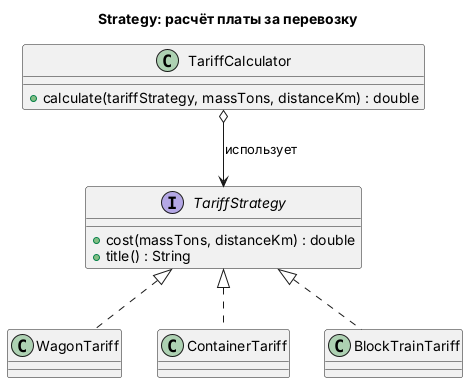

In [ ]:
!plantuml -tpng strategy.puml
from IPython.display import Image
Image("strategy.png")

### 2.5 Вопросы к образцу (ответить текстом в этой ячейке)

1. Какие классы пришлось бы изменить в коде «до» и в коде «после», чтобы добавить рефрижераторную отправку?
   **Ответ:** В коде «до» — класс `TariffBefore`: нужно залезть внутрь работающего метода `cost` и добавить ещё одну ветку `else if`, то есть изменить уже протестированный код. В коде «после» ни один существующий класс менять не нужно: `TariffStrategy`, `TariffCalculator` и три прежние стратегии остаются как есть, достаточно написать **новый** класс (например, `RefrigeratedTariff implements TariffStrategy`) и положить его в каталог стратегий там, где этот каталог собирается (в тесте для этого использован анонимный класс).
2. Зачем в файле оставлен метод `legacyCost`, если он больше не используется в расчёте?
   **Ответ:** Это эталон поведения для **характеризующих тестов**: он хранит результаты старой реализации, и проверки `[OK]` сравнивают с ними новые стратегии. Так доказывается, что рефакторинг не изменил поведение (повагонная, контейнерная и маршрутная отправки дают те же суммы). Без эталона нечем подтвердить, что код после переписывания считает так же, как и раньше. Кроме того, `legacyCost` показывает, что в старом коде рефрижератор давал 0.00.
3. Что произойдёт, если в каталоге не окажется запрошенного вида отправки, и как это следует обработать?
   **Ответ:** `tariffCatalog.get(...)` вернёт `null`, и вызов `tariffCalculator.calculate(null, ...)` завершится `NullPointerException` без понятного сообщения. Обработать нужно явно: проверить `containsKey` и бросить `IllegalArgumentException("Неизвестный вид отправки: ...")`, либо вернуть `Optional`, либо (если так решено бизнесом) использовать стратегию по умолчанию. Тихий ноль, как в коде «до», — худший вариант: неверная плата выглядит как правильная.

---

## 3. Задача 1: Factory Method

**Вариант 8 — «Пригородные перевозки».** Фабрика создаёт **тип абонемента**.

**Сценарий.** Описание абонемента по его типу: месячный, студенческий, выходного дня. Ниже — код «до», построенный на той же ошибке: условный оператор вместо полиморфизма (предметная область переведена на вариант 8).

### 3.1 Код «до» (запустить, не изменяя)

In [ ]:
%%writefile FactoryBefore.java
// Код «до»: создание и описание объекта подменены разбором строкового типа.
public class FactoryBefore {

    public static void main(String[] args) {
        System.out.println(describe("MONTHLY", 30));
        System.out.println(describe("STUDENT", 30));
        System.out.println(describe("WEEKEND", 90));
        System.out.println(describe("SEASONAL", 180));   // новый тип — обработчика нет
    }

    static String describe(String subscriptionType, int validityDays) {
        if (subscriptionType.equals("MONTHLY")) {
            return "Месячный абонемент: срок действия " + validityDays + " дн., неограниченное число поездок в выбранных зонах";
        } else if (subscriptionType.equals("STUDENT")) {
            return "Студенческий абонемент: срок действия " + validityDays + " дн., льготный тариф по студенческому билету";
        } else if (subscriptionType.equals("WEEKEND")) {
            return "Абонемент выходного дня: срок действия " + validityDays + " дн., поездки в субботу, воскресенье и праздничные дни";
        }
        return "Неизвестный тип абонемента: " + subscriptionType;
    }
}

Writing FactoryBefore.java


In [ ]:
!java FactoryBefore.java

Месячный абонемент: срок действия 30 дн., неограниченное число поездок в выбранных зонах
Студенческий абонемент: срок действия 30 дн., льготный тариф по студенческому билету
Абонемент выходного дня: срок действия 90 дн., поездки в субботу, воскресенье и праздничные дни
Неизвестный тип абонемента: SEASONAL


### 3.2 Задание

Переписать сценарий на **Factory Method** в файле `FactoryAfter.java`. Требования:

1. Общий тип продукта: интерфейс или абстрактный класс `Subscription` с методами `description()` и `validityDays()`.
2. Не менее трёх конкретных продуктов: `MonthlySubscription`, `StudentSubscription`, `WeekendSubscription`.
3. Создатель с фабричным методом: абстрактный класс или интерфейс `SubscriptionCreator` с методом `createSubscription(int validityDays)` и конкретные создатели для каждого типа.
4. Вызывающий код (`main`) работает **только** с типами `SubscriptionCreator` и `Subscription` и не содержит ни одного `if` по типу абонемента.
5. Четвёртый тип (`SeasonalSubscription`, сезонный дачный абонемент) добавляется **новым классом**, без правки ранее написанных классов; это должно быть видно по коду.
6. Проверки в файле (метод `check`, как в образце), минимум четыре:
   * описание каждого из трёх типов не пустое и содержит срок действия;
   * тип созданного объекта соответствует ожидаемому создателю;
   * четвёртый тип работает наравне с остальными;
   * метод `main` не содержит разбора типов (проверяется глазами преподавателя, в код выносить не нужно).
7. При неуспешной проверке — `throw new AssertionError(...)`.

**Подсказка по структуре файла:** первым идёт `public class FactoryAfter` с `main`, после него — интерфейсы и классы паттерна (как в `TariffAfter.java`).

In [ ]:
%%writefile FactoryAfter.java
// Код «после»: Factory Method. Каждый тип абонемента создаёт свой создатель.
import java.util.LinkedHashMap;
import java.util.Map;

public class FactoryAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Каталог создателей: вызывающий код знает только тип SubscriptionCreator,
        // но не конкретные классы абонементов и не разбирает тип условным оператором
        Map<String, SubscriptionCreator> creatorCatalog = new LinkedHashMap<>();
        creatorCatalog.put("MONTHLY", new MonthlySubscriptionCreator());
        creatorCatalog.put("STUDENT", new StudentSubscriptionCreator());
        creatorCatalog.put("WEEKEND", new WeekendSubscriptionCreator());

        Map<String, Integer> validityCatalog = new LinkedHashMap<>();
        validityCatalog.put("MONTHLY", 30);
        validityCatalog.put("STUDENT", 30);
        validityCatalog.put("WEEKEND", 90);

        Map<String, Class<? extends Subscription>> expectedProductCatalog = new LinkedHashMap<>();
        expectedProductCatalog.put("MONTHLY", MonthlySubscription.class);
        expectedProductCatalog.put("STUDENT", StudentSubscription.class);
        expectedProductCatalog.put("WEEKEND", WeekendSubscription.class);

        System.out.println("--- Выдача абонементов через создателей ---");
        for (Map.Entry<String, SubscriptionCreator> catalogEntry : creatorCatalog.entrySet()) {
            int validityDays = validityCatalog.get(catalogEntry.getKey());
            System.out.println(catalogEntry.getValue().issue(validityDays));
        }

        System.out.println();
        System.out.println("--- Характеризующие тесты: поведение совпадает с кодом «до» ---");
        for (Map.Entry<String, SubscriptionCreator> catalogEntry : creatorCatalog.entrySet()) {
            String subscriptionType = catalogEntry.getKey();
            int validityDays = validityCatalog.get(subscriptionType);
            Subscription createdSubscription = catalogEntry.getValue().createSubscription(validityDays);

            check(subscriptionType + ": описание не пустое и содержит срок действия",
                    !createdSubscription.description().isEmpty()
                            && createdSubscription.description().contains(String.valueOf(validityDays)));
            check(subscriptionType + ": создатель вернул ожидаемый тип абонемента",
                    expectedProductCatalog.get(subscriptionType).isInstance(createdSubscription));
            check(subscriptionType + ": описание совпадает с описанием из кода «до»",
                    createdSubscription.description().equals(legacyDescribe(subscriptionType, validityDays)));
        }

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: четвёртый тип добавлен новыми классами ---");
        // Классы SeasonalSubscription и SeasonalSubscriptionCreator описаны в конце файла;
        // ни один из ранее написанных классов не изменялся
        SubscriptionCreator seasonalCreator = new SeasonalSubscriptionCreator();
        Subscription seasonalSubscription = seasonalCreator.createSubscription(180);
        System.out.println(seasonalCreator.issue(180));
        check("новый тип работает через тот же интерфейс SubscriptionCreator",
                seasonalSubscription instanceof SeasonalSubscription
                        && seasonalSubscription.description().contains("180"));
        check("в коде «до» тот же тип давал «неизвестный тип»",
                legacyDescribe("SEASONAL", 180).startsWith("Неизвестный тип"));
        check("общая логика выдачи из SubscriptionCreator сработала для нового типа без правок",
                seasonalCreator.issue(180).startsWith("Выдан: ")
                        && seasonalCreator.issue(180).contains(seasonalSubscription.description()));

        finishChecks();
    }

    // --- служебное ---

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    // Итог вынесен из main, чтобы в самом main не было ветвлений
    static void finishChecks() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // Старая реализация сохранена только как эталон поведения для характеризующих тестов
    static String legacyDescribe(String subscriptionType, int validityDays) {
        if (subscriptionType.equals("MONTHLY")) {
            return "Месячный абонемент: срок действия " + validityDays + " дн., неограниченное число поездок в выбранных зонах";
        } else if (subscriptionType.equals("STUDENT")) {
            return "Студенческий абонемент: срок действия " + validityDays + " дн., льготный тариф по студенческому билету";
        } else if (subscriptionType.equals("WEEKEND")) {
            return "Абонемент выходного дня: срок действия " + validityDays + " дн., поездки в субботу, воскресенье и праздничные дни";
        }
        return "Неизвестный тип абонемента: " + subscriptionType;
    }
}

// --- участники паттерна Factory Method ---

/** Продукт: общий интерфейс всех абонементов. */
interface Subscription {
    String description();
    int validityDays();
}

/** Создатель: объявляет фабричный метод и использует продукт, не зная его конкретного класса. */
abstract class SubscriptionCreator {

    /** Фабричный метод: конкретный тип абонемента выбирает подкласс. */
    abstract Subscription createSubscription(int validityDays);

    /** Общая логика выдачи одинакова для всех типов и работает только с интерфейсом Subscription. */
    String issue(int validityDays) {
        Subscription issuedSubscription = createSubscription(validityDays);
        return "Выдан: " + issuedSubscription.description();
    }
}

// --- конкретные продукты ---

class MonthlySubscription implements Subscription {
    private final int validityDays;
    MonthlySubscription(int validityDays) {
        this.validityDays = validityDays;
    }
    public String description() {
        return "Месячный абонемент: срок действия " + validityDays + " дн., неограниченное число поездок в выбранных зонах";
    }
    public int validityDays() {
        return validityDays;
    }
}

class StudentSubscription implements Subscription {
    private final int validityDays;
    StudentSubscription(int validityDays) {
        this.validityDays = validityDays;
    }
    public String description() {
        return "Студенческий абонемент: срок действия " + validityDays + " дн., льготный тариф по студенческому билету";
    }
    public int validityDays() {
        return validityDays;
    }
}

class WeekendSubscription implements Subscription {
    private final int validityDays;
    WeekendSubscription(int validityDays) {
        this.validityDays = validityDays;
    }
    public String description() {
        return "Абонемент выходного дня: срок действия " + validityDays + " дн., поездки в субботу, воскресенье и праздничные дни";
    }
    public int validityDays() {
        return validityDays;
    }
}

// --- конкретные создатели ---

class MonthlySubscriptionCreator extends SubscriptionCreator {
    Subscription createSubscription(int validityDays) {
        return new MonthlySubscription(validityDays);
    }
}

class StudentSubscriptionCreator extends SubscriptionCreator {
    Subscription createSubscription(int validityDays) {
        return new StudentSubscription(validityDays);
    }
}

class WeekendSubscriptionCreator extends SubscriptionCreator {
    Subscription createSubscription(int validityDays) {
        return new WeekendSubscription(validityDays);
    }
}

// --- РАСШИРЕНИЕ: четвёртый тип добавлен только новыми классами ---

class SeasonalSubscription implements Subscription {
    private final int validityDays;
    SeasonalSubscription(int validityDays) {
        this.validityDays = validityDays;
    }
    public String description() {
        return "Сезонный (дачный) абонемент: срок действия " + validityDays + " дн., поездки по дачным направлениям в тёплый сезон";
    }
    public int validityDays() {
        return validityDays;
    }
}

class SeasonalSubscriptionCreator extends SubscriptionCreator {
    Subscription createSubscription(int validityDays) {
        return new SeasonalSubscription(validityDays);
    }
}

Writing FactoryAfter.java


In [ ]:
!java FactoryAfter.java

--- Выдача абонементов через создателей ---
Выдан: Месячный абонемент: срок действия 30 дн., неограниченное число поездок в выбранных зонах
Выдан: Студенческий абонемент: срок действия 30 дн., льготный тариф по студенческому билету
Выдан: Абонемент выходного дня: срок действия 90 дн., поездки в субботу, воскресенье и праздничные дни

--- Характеризующие тесты: поведение совпадает с кодом «до» ---
[OK]   MONTHLY: описание не пустое и содержит срок действия
[OK]   MONTHLY: создатель вернул ожидаемый тип абонемента
[OK]   MONTHLY: описание совпадает с описанием из кода «до»
[OK]   STUDENT: описание не пустое и содержит срок действия
[OK]   STUDENT: создатель вернул ожидаемый тип абонемента
[OK]   STUDENT: описание совпадает с описанием из кода «до»
[OK]   WEEKEND: описание не пустое и содержит срок действия
[OK]   WEEKEND: создатель вернул ожидаемый тип абонемента
[OK]   WEEKEND: описание совпадает с описанием из кода «до»

--- Тест открытости/закрытости: четвёртый тип добавлен новыми кла

In [ ]:
%%writefile factory.puml
@startuml
title Factory Method: выдача абонемента

interface Subscription {
  +description() : String
  +validityDays() : int
}

abstract class SubscriptionCreator {
  +{abstract} createSubscription(validityDays) : Subscription
  +issue(validityDays) : String
}

class MonthlySubscription
class StudentSubscription
class WeekendSubscription
class SeasonalSubscription

class MonthlySubscriptionCreator
class StudentSubscriptionCreator
class WeekendSubscriptionCreator
class SeasonalSubscriptionCreator

Subscription <|.. MonthlySubscription
Subscription <|.. StudentSubscription
Subscription <|.. WeekendSubscription
Subscription <|.. SeasonalSubscription

SubscriptionCreator <|-- MonthlySubscriptionCreator
SubscriptionCreator <|-- StudentSubscriptionCreator
SubscriptionCreator <|-- WeekendSubscriptionCreator
SubscriptionCreator <|-- SeasonalSubscriptionCreator

SubscriptionCreator ..> Subscription : использует
MonthlySubscriptionCreator ..> MonthlySubscription : создаёт
StudentSubscriptionCreator ..> StudentSubscription : создаёт
WeekendSubscriptionCreator ..> WeekendSubscription : создаёт
SeasonalSubscriptionCreator ..> SeasonalSubscription : создаёт

note right of SeasonalSubscriptionCreator
  Четвёртый тип добавлен
  только новыми классами
end note
@enduml

Writing factory.puml


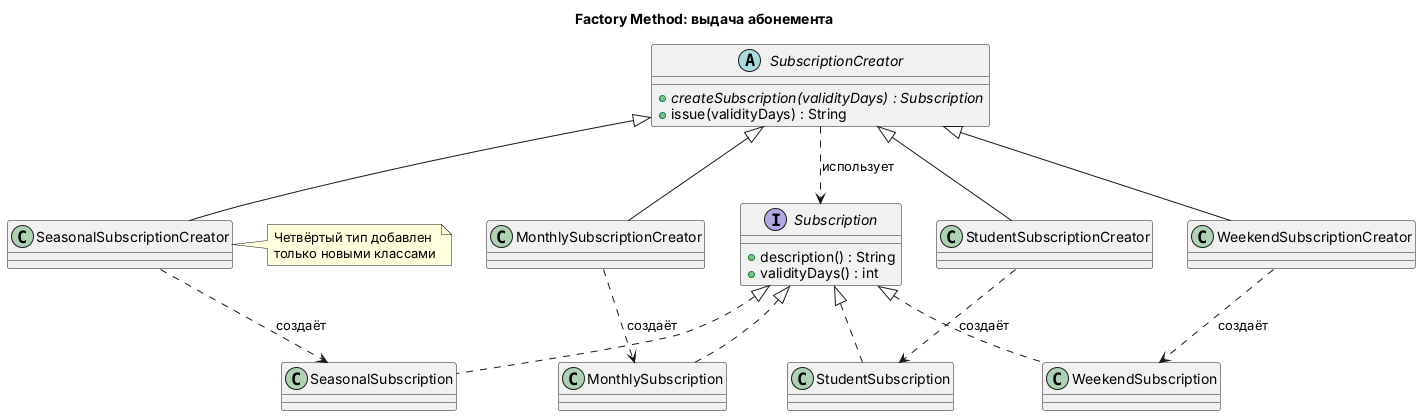

In [ ]:
!plantuml -tpng factory.puml
from IPython.display import Image
Image("factory.png")

**Вывод по задаче 1** (чем создание через фабричный метод отличается от создания через `new` в вызывающем коде, и когда фабрика излишня):

При `new MonthlySubscription(...)` вызывающий код сам называет конкретный класс: он привязан к нему и при появлении нового типа его приходится править (или снова писать `if` по типу, как в `FactoryBefore`). В Factory Method вызывающий код получает объект через `SubscriptionCreator.createSubscription(...)` и работает только с интерфейсом `Subscription`; какой именно класс создавать, решает подкласс создателя. Поэтому сезонный абонемент добавился двумя новыми классами (`SeasonalSubscription` и `SeasonalSubscriptionCreator`), а `main`, интерфейс и три прежних типа остались без изменений. Дополнительная выгода: общая логика выдачи `issue(...)` написана один раз в `SubscriptionCreator` и работает для любого типа.

Фабрика излишня, когда тип один и не предвидится новых (достаточно обычного конструктора), когда варианты различаются только данными, а не поведением (хватит одного класса с полем или `enum`), и когда выбор типа делается в одном месте и не размножается по коду. Тогда фабричный метод лишь удваивает число классов (продукт + создатель на каждый тип) без пользы.

---

## 4. Задача 2: Observer

**Вариант 8 — «Пригородные перевозки».** Событие: **изменено расписание**.

**Сценарий.** Расписание пригородного маршрута фиксирует изменение времени отправления поезда и должно оповестить получателей: табло, журнал, рассылку. В коде «до» расписание (`Timetable`) само знает про всех получателей.

### 4.1 Код «до» (запустить, не изменяя)

In [ ]:
%%writefile ObserverBefore.java
// Код «до»: источник события жёстко связан со всеми получателями.
public class ObserverBefore {

    public static void main(String[] args) {
        Timetable timetable = new Timetable("Гомель — Жлобин");
        timetable.scheduleChanged("6401", "08:15");
        timetable.scheduleChanged("6405", "17:40");
    }
}

class Timetable {

    private final String routeName;

    Timetable(String routeName) {
        this.routeName = routeName;
    }

    void scheduleChanged(String trainNumber, String newDepartureTime) {
        // Любой новый получатель требует правки этого метода
        System.out.println("[табло]  Расписание изменено: поезд " + trainNumber
                + " (" + routeName + ") отправляется в " + newDepartureTime);
        System.out.println("[журнал] " + routeName + ": изменено расписание поезда " + trainNumber
                + ", новое время отправления " + newDepartureTime);
    }
}

Writing ObserverBefore.java


In [ ]:
!java ObserverBefore.java

[табло]  Расписание изменено: поезд 6401 (Гомель — Жлобин) отправляется в 08:15
[журнал] Гомель — Жлобин: изменено расписание поезда 6401, новое время отправления 08:15
[табло]  Расписание изменено: поезд 6405 (Гомель — Жлобин) отправляется в 17:40
[журнал] Гомель — Жлобин: изменено расписание поезда 6405, новое время отправления 17:40


### 4.2 Задание

Переписать сценарий на **Observer** в файле `ObserverAfter.java`. Требования:

1. Интерфейс наблюдателя `ScheduleChangeListener` с методом `onScheduleChanged(String routeName, String trainNumber, String newDepartureTime)`.
2. Субъект `Timetable` с методами `addListener`, `removeListener`, `scheduleChanged`; класс `Timetable` **не знает**, какие именно наблюдатели существуют.
3. Не менее трёх наблюдателей: табло, журнал, рассылка. Журнал должен **накапливать** записи, чтобы их можно было проверить.
4. Четвёртый наблюдатель (например, передача в АСУ) добавляется без правки класса `Timetable`.
5. Проверки в файле, минимум четыре:
   * после одного события журнал получил ровно одну запись;
   * после отписки наблюдателя его записи больше не появляются;
   * все подписчики получили одно и то же событие;
   * добавление четвёртого наблюдателя не потребовало изменения `Timetable`.
6. В выводе указать порядок получения события подписчиками и ответить на вопрос в выводе ниже.

**Подсказка:** список наблюдателей удобно хранить в `java.util.ArrayList`, обход — обычным `for`.

In [ ]:
%%writefile ObserverAfter.java
// Код «после»: Observer. Расписание (субъект) не знает, кто именно подписан на изменения.
import java.util.ArrayList;
import java.util.List;

public class ObserverAfter {

    private static int failedChecks = 0;

    public static void main(String[] args) {

        // Общий список нужен только для проверки: в каком порядке подписчики получили событие
        List<String> deliveryOrder = new ArrayList<>();

        Timetable timetable = new Timetable("Гомель — Жлобин");
        InformationBoard informationBoard = new InformationBoard(deliveryOrder);
        ChangeLog changeLog = new ChangeLog(deliveryOrder);
        PassengerMailing passengerMailing = new PassengerMailing(deliveryOrder);

        timetable.addListener(informationBoard);
        timetable.addListener(changeLog);
        timetable.addListener(passengerMailing);

        System.out.println("--- Событие 1: подписаны табло, журнал и рассылка ---");
        timetable.scheduleChanged("6401", "08:15");

        System.out.println();
        System.out.println("--- Проверки после первого события ---");
        check("журнал получил ровно одну запись", changeLog.receivedEvents().size() == 1);
        check("все подписчики получили одно и то же событие",
                informationBoard.receivedEvents().equals(changeLog.receivedEvents())
                        && changeLog.receivedEvents().equals(passengerMailing.receivedEvents()));
        check("табло и журнал печатают те же строки, что код «до»",
                informationBoard.lastLine().equals(legacyBoardLine("Гомель — Жлобин", "6401", "08:15"))
                        && changeLog.lastLine().equals(legacyJournalLine("Гомель — Жлобин", "6401", "08:15")));
        check("порядок получения совпадает с порядком подписки",
                deliveryOrder.equals(List.of("табло", "журнал", "рассылка")));
        System.out.println("Порядок получения события: " + String.join(" → ", deliveryOrder));

        System.out.println();
        System.out.println("--- Событие 2: рассылка отписана ---");
        timetable.removeListener(passengerMailing);
        timetable.scheduleChanged("6405", "17:40");
        check("после отписки записи рассылки больше не появляются",
                passengerMailing.receivedEvents().size() == 1);
        check("остальные подписчики продолжают получать события",
                changeLog.receivedEvents().size() == 2 && informationBoard.receivedEvents().size() == 2);

        System.out.println();
        System.out.println("--- Тест открытости/закрытости: четвёртый наблюдатель без правки Timetable ---");
        // Класс AsuTransmitter описан в конце файла; класс Timetable не изменялся
        AsuTransmitter asuTransmitter = new AsuTransmitter(deliveryOrder);
        timetable.addListener(asuTransmitter);
        timetable.scheduleChanged("6410", "21:05");
        check("четвёртый наблюдатель получил событие наравне с остальными",
                asuTransmitter.receivedEvents().size() == 1
                        && asuTransmitter.receivedEvents().get(0).equals(changeLog.receivedEvents().get(2)));
        check("Timetable не хранит ссылок на конкретные классы наблюдателей",
                !timetableKnowsConcreteListeners());

        System.out.println();
        System.out.println("--- Устойчивость: ошибка одного подписчика не мешает остальным ---");
        ScheduleChangeListener faultyListener = new ScheduleChangeListener() {
            public void onScheduleChanged(String routeName, String trainNumber, String newDepartureTime) {
                throw new IllegalStateException("сбой подписчика");
            }
        };
        timetable.addListener(faultyListener);
        timetable.scheduleChanged("6412", "22:10");
        check("после сбоя одного подписчика событие дошло до журнала",
                changeLog.receivedEvents().size() == 4);

        finishChecks();
    }

    // --- служебное ---

    static void check(String checkName, boolean passed) {
        System.out.println((passed ? "[OK]   " : "[FAIL] ") + checkName);
        if (!passed) {
            failedChecks++;
        }
    }

    static void finishChecks() {
        if (failedChecks > 0) {
            throw new AssertionError("не пройдено проверок: " + failedChecks);
        }
        System.out.println();
        System.out.println("Все проверки пройдены.");
    }

    // Строки из кода «до», сохранены как эталон для характеризующих тестов
    static String legacyBoardLine(String routeName, String trainNumber, String newDepartureTime) {
        return "[табло]  Расписание изменено: поезд " + trainNumber
                + " (" + routeName + ") отправляется в " + newDepartureTime;
    }

    static String legacyJournalLine(String routeName, String trainNumber, String newDepartureTime) {
        return "[журнал] " + routeName + ": изменено расписание поезда " + trainNumber
                + ", новое время отправления " + newDepartureTime;
    }

    // Проверка по полям: субъект должен хранить только интерфейс наблюдателя, но не его реализации
    static boolean timetableKnowsConcreteListeners() {
        for (java.lang.reflect.Field declaredField : Timetable.class.getDeclaredFields()) {
            Class<?> fieldType = declaredField.getType();
            if (ScheduleChangeListener.class.isAssignableFrom(fieldType) && !fieldType.isInterface()) {
                return true;
            }
        }
        return false;
    }
}

// --- участники паттерна Observer ---

/** Наблюдатель: общий интерфейс всех получателей события. */
interface ScheduleChangeListener {
    void onScheduleChanged(String routeName, String trainNumber, String newDepartureTime);
}

/** Субъект: хранит список наблюдателей и оповещает их, не зная их конкретных классов. */
class Timetable {

    private final String routeName;
    private final List<ScheduleChangeListener> scheduleListeners = new ArrayList<>();

    Timetable(String routeName) {
        this.routeName = routeName;
    }

    void addListener(ScheduleChangeListener scheduleListener) {
        scheduleListeners.add(scheduleListener);
    }

    void removeListener(ScheduleChangeListener scheduleListener) {
        scheduleListeners.remove(scheduleListener);
    }

    void scheduleChanged(String trainNumber, String newDepartureTime) {
        // Обход копии: наблюдатель может отписаться прямо во время оповещения
        List<ScheduleChangeListener> listenersSnapshot = new ArrayList<>(scheduleListeners);
        for (ScheduleChangeListener scheduleListener : listenersSnapshot) {
            try {
                scheduleListener.onScheduleChanged(routeName, trainNumber, newDepartureTime);
            } catch (RuntimeException listenerFailure) {
                // Сбой одного подписчика не должен лишать события всех остальных
                System.out.println("[сбой подписчика] " + listenerFailure.getMessage());
            }
        }
    }
}

/** Общая часть конкретных наблюдателей: накапливает полученные события и печатает строку вывода. */
abstract class RecordingListener implements ScheduleChangeListener {

    private final List<String> receivedEvents = new ArrayList<>();
    private final List<String> deliveryOrder;
    private final String listenerName;
    private String lastLine = "";

    RecordingListener(String listenerName, List<String> deliveryOrder) {
        this.listenerName = listenerName;
        this.deliveryOrder = deliveryOrder;
    }

    /** Формат строки у каждого получателя свой. */
    abstract String formatLine(String routeName, String trainNumber, String newDepartureTime);

    public void onScheduleChanged(String routeName, String trainNumber, String newDepartureTime) {
        receivedEvents.add(routeName + "|" + trainNumber + "|" + newDepartureTime);
        deliveryOrder.add(listenerName);
        lastLine = formatLine(routeName, trainNumber, newDepartureTime);
        System.out.println(lastLine);
    }

    List<String> receivedEvents() {
        return receivedEvents;
    }

    String lastLine() {
        return lastLine;
    }
}

// --- конкретные наблюдатели ---

class InformationBoard extends RecordingListener {
    InformationBoard(List<String> deliveryOrder) {
        super("табло", deliveryOrder);
    }
    String formatLine(String routeName, String trainNumber, String newDepartureTime) {
        return "[табло]  Расписание изменено: поезд " + trainNumber
                + " (" + routeName + ") отправляется в " + newDepartureTime;
    }
}

class ChangeLog extends RecordingListener {
    ChangeLog(List<String> deliveryOrder) {
        super("журнал", deliveryOrder);
    }
    String formatLine(String routeName, String trainNumber, String newDepartureTime) {
        return "[журнал] " + routeName + ": изменено расписание поезда " + trainNumber
                + ", новое время отправления " + newDepartureTime;
    }
}

class PassengerMailing extends RecordingListener {
    PassengerMailing(List<String> deliveryOrder) {
        super("рассылка", deliveryOrder);
    }
    String formatLine(String routeName, String trainNumber, String newDepartureTime) {
        return "[рассылка] Владельцам абонементов направлено уведомление: поезд " + trainNumber
                + " теперь отправляется в " + newDepartureTime;
    }
}

// --- РАСШИРЕНИЕ: четвёртый наблюдатель добавлен новым классом, Timetable не менялся ---

class AsuTransmitter extends RecordingListener {
    AsuTransmitter(List<String> deliveryOrder) {
        super("АСУ", deliveryOrder);
    }
    String formatLine(String routeName, String trainNumber, String newDepartureTime) {
        return "[АСУ]    Передано в систему управления: маршрут " + routeName
                + ", поезд " + trainNumber + ", отправление " + newDepartureTime;
    }
}

Writing ObserverAfter.java


In [ ]:
!java ObserverAfter.java

--- Событие 1: подписаны табло, журнал и рассылка ---
[табло]  Расписание изменено: поезд 6401 (Гомель — Жлобин) отправляется в 08:15
[журнал] Гомель — Жлобин: изменено расписание поезда 6401, новое время отправления 08:15
[рассылка] Владельцам абонементов направлено уведомление: поезд 6401 теперь отправляется в 08:15

--- Проверки после первого события ---
[OK]   журнал получил ровно одну запись
[OK]   все подписчики получили одно и то же событие
[OK]   табло и журнал печатают те же строки, что код «до»
[OK]   порядок получения совпадает с порядком подписки
Порядок получения события: табло → журнал → рассылка

--- Событие 2: рассылка отписана ---
[табло]  Расписание изменено: поезд 6405 (Гомель — Жлобин) отправляется в 17:40
[журнал] Гомель — Жлобин: изменено расписание поезда 6405, новое время отправления 17:40
[OK]   после отписки записи рассылки больше не появляются
[OK]   остальные подписчики продолжают получать события

--- Тест открытости/закрытости: четвёртый наблюдатель без пр

In [ ]:
%%writefile observer.puml
@startuml
title Observer: оповещение об изменении расписания

interface ScheduleChangeListener {
  +onScheduleChanged(routeName, trainNumber, newDepartureTime)
}

class Timetable {
  -routeName : String
  -scheduleListeners : List<ScheduleChangeListener>
  +addListener(scheduleListener)
  +removeListener(scheduleListener)
  +scheduleChanged(trainNumber, newDepartureTime)
}

abstract class RecordingListener {
  -receivedEvents : List<String>
  +onScheduleChanged(routeName, trainNumber, newDepartureTime)
  +{abstract} formatLine(routeName, trainNumber, newDepartureTime) : String
  +receivedEvents() : List<String>
}

class InformationBoard
class ChangeLog
class PassengerMailing
class AsuTransmitter

Timetable o--> "0..*" ScheduleChangeListener : оповещает
ScheduleChangeListener <|.. RecordingListener
RecordingListener <|-- InformationBoard
RecordingListener <|-- ChangeLog
RecordingListener <|-- PassengerMailing
RecordingListener <|-- AsuTransmitter

note right of AsuTransmitter
  Четвёртый наблюдатель добавлен
  без правки класса Timetable
end note
@enduml

Writing observer.puml


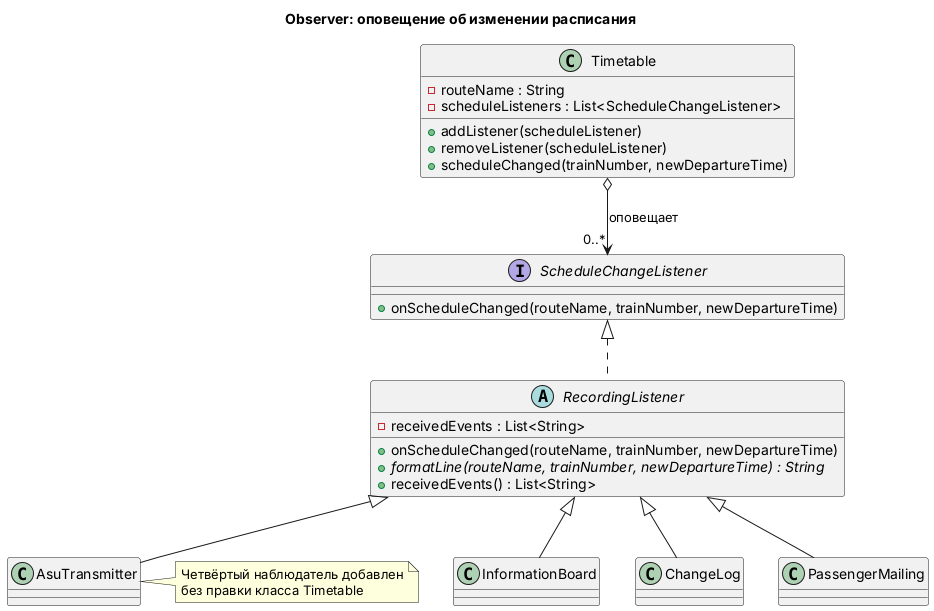

In [ ]:
!plantuml -tpng observer.puml
from IPython.display import Image
Image("observer.png")

**Вывод по задаче 2** (какую связанность снял Observer и какие новые проблемы он создал — порядок уведомлений, ошибка в одном подписчике, забытая отписка):

**Порядок получения события** (из вывода `ObserverAfter.java`): табло → журнал → рассылка (а после подключения четвёртого — ещё АСУ). Он совпадает с порядком подписки, потому что наблюдатели лежат в `ArrayList` и обходятся по очереди; это проверяется отдельной проверкой.

**Какую связанность снял Observer.** В `ObserverBefore` метод `Timetable.scheduleChanged` сам печатал в табло и журнал, то есть расписание знало всех получателей и любой новый получатель требовал править этот метод. Теперь `Timetable` зависит только от интерфейса `ScheduleChangeListener`: рассылка и АСУ подключаются и отключаются во время работы (`addListener` / `removeListener`), а класс `Timetable` не менялся (проверка по полям класса это подтверждает).

**Какие проблемы появились.**
* *Порядок уведомлений* не гарантирован контрактом: код не должен рассчитывать на то, что табло обновится раньше журнала. У нас порядок — следствие реализации.
* *Ошибка в одном подписчике*: исключение прервало бы цикл, и остальные не получили бы событие. Поэтому в `Timetable.scheduleChanged` вызов каждого подписчика обёрнут в `try/catch`, а обход идёт по копии списка (подписчик может отписаться прямо во время оповещения). Последнее проверено отдельным тестом со сбойным подписчиком.
* *Забытая отписка*: `Timetable` хранит сильные ссылки на подписчиков, поэтому не отписанный объект не соберёт сборщик мусора, и он продолжит получать события (утечка памяти). Подписчик должен отписываться, когда перестаёт быть нужным.
* Оповещение синхронное: медленный подписчик (например, рассылка) задерживает всех остальных.

## 5. Сравнение и выводы

### 5.1 Итоговая таблица

| Паттерн | Какую проблему кода «до» устраняет | Что добавляется без правки старого кода | Чем приходится заплатить | Где применим в вашем проекте |
|---|---|---|---|---|
| Strategy | Один метод с цепочкой `if` выбирает и считает; нарушены открытость/закрытость и единственная ответственность | Новый вид отправки (или тарификация) — новым классом-стратегией | Больше классов; вызывающий код должен выбрать стратегию; нужен обработчик «неизвестной» стратегии | Тарификация по зонам в пригородных перевозках: каждая схема (по числу зон, по расстоянию, льготная) — своя стратегия |
| Factory Method | Вызывающий код сам разбирает тип и создаёт объекты, зная все конкретные классы | Новый тип абонемента — новыми классами продукта и создателя | На каждый тип по два класса; параллельные иерархии продуктов и создателей | Создание абонементов: месячный, студенческий, выходного дня, сезонный |
| Observer | Субъект знает всех получателей и правится при каждом новом получателе | Новый получатель события (АСУ, SMS, приложение) — новым классом-подписчиком | Нет гарантии порядка, сбой подписчика, утечки при забытой отписке, синхронная доставка | Оповещение об изменении расписания: табло, журнал, рассылка, АСУ |

### 5.2 Контрольные вопросы

1. Какой принцип SOLID нарушает разбор типа условным оператором и как каждый из трёх паттернов его восстанавливает?
   **Ответ:** Принцип открытости/закрытости (OCP): для нового типа приходится править готовый метод; заодно страдает единственная ответственность (SRP). Strategy выносит каждый вариант расчёта в свой класс с общим интерфейсом, и новый вариант добавляется без правки контекста. Factory Method переносит выбор создаваемого класса в подклассы создателя, вызывающий код зависит от абстракций (OCP и принцип инверсии зависимостей, DIP). Observer заставляет субъект зависеть только от интерфейса наблюдателя, и новые получатели подключаются без правки субъекта.
2. Чем Factory Method отличается от статического метода создания (`static factory method`) и от Abstract Factory?
   **Ответ:** Статический фабричный метод — обычный `static`-метод класса (например, `List.of`), внутри которого выбор реализации чаще всего жёстко прописан (нередко тем же `switch`); его нельзя переопределить и подменить наследованием. Factory Method — паттерн GoF: виртуальный метод создателя, который переопределяют подклассы, и именно подкласс решает, какой продукт создать. Abstract Factory — интерфейс для создания **семейства** согласованных между собой объектов (несколько фабричных методов); Factory Method создаёт один продукт.
3. Strategy и State имеют почти одинаковую структуру классов. В чём разница по назначению?
   **Ответ:** Strategy — это взаимозаменяемые алгоритмы: клиент выбирает стратегию снаружи, стратегии не знают друг о друге, а объект обычно сохраняет её надолго. State — поведение объекта зависит от его внутреннего состояния: состояния сами переключают друг друга (знают о переходах), клиент их не выбирает.
4. Почему Observer может привести к утечке памяти и как этого избежать?
   **Ответ:** Субъект хранит сильные ссылки на подписчиков, поэтому подписчик, на которого больше никто не ссылается, всё равно остаётся в списке и не удаляется сборщиком мусора (проблема «забытого слушателя»). Избежать: отписываться в конце жизненного цикла (`removeListener`), возвращать при подписке объект-подписку с `close()` (`AutoCloseable`), хранить слабые ссылки (`WeakReference`, `WeakHashMap`), ограничивать время жизни подписки.
5. Приведите пример, когда введение паттерна **вредно**. Что такое преждевременное усложнение?
   **Ответ:** Если в пригородных перевозках существует единственный вид абонемента и новых не планируется, фабрика на него (интерфейс, продукт, создатель, ещё и каталог) только добавляет классы и косвенность. Так же, если схема тарификации одна и не меняется, стратегия с интерфейсом не нужна. Преждевременное усложнение — это введение гибкости «на будущее», которая не нужна по текущим требованиям (нарушение YAGNI): код читается и сопровождается тяжелее, а ожидаемые изменения так и не приходят. Паттерн оправдан, когда вариативность уже есть или вот-вот появится.

### 5.3 Три вывода по работе в целом

1. Цепочка `if` по строковому типу работает, но «закрывает» код для расширения: рефрижератор в тарифе, `SEASONAL` в абонементах и новый получатель оповещения требовали бы правки готовых методов. Паттерны переносят вариативность в новые классы.
2. Безопасность рефакторинга обеспечивают проверки: характеризующие тесты сравнивают новый код с эталоном «до» (`legacyCost`, `legacyDescribe`, `legacyBoardLine`), а тесты расширения доказывают, что четвёртый вариант добавляется без правки старого кода.
3. У паттернов есть цена: больше классов, косвенность, а у Observer — порядок уведомлений, сбои подписчиков и утечки при забытой отписке. Применять их нужно там, где вариативность реальна, а не «на всякий случай».

---

## 6. Варианты предметных областей

Номер варианта — по номеру студента в списке группы. Образец (раздел 2) выполняется всеми одинаково; задачи 1 и 2 — на своей предметной области.

| № | Предметная область | Фабрика создаёт | Стратегия варьирует | Наблюдатели получают событие |
|---|---|---|---|---|
| 1 | Грузовая станция | тип вагона | расчёт платы за пользование вагонами | вагон подан под погрузку |
| 2 | Локомотивное депо | вид ремонта (ТО-2, ТР-1, ТР-2) | приоритет заявок на ремонт | локомотив выдан из ремонта |
| 3 | Пассажирская касса | тип проездного документа | начисление скидки | рейс задержан |
| 4 | Контейнерный терминал | тип контейнера | выбор места на площадке | контейнер прибыл |
| 5 | Автотранспортное предприятие | тип транспортного средства | расчёт расхода топлива | путевой лист закрыт |
| 6 | Склад | тип тары | правило размещения (FIFO, ABC) | запас ниже нормы |
| 7 | Сортировочная станция | тип отцепа | очерёдность расформирования | состав расформирован |
| 8 | Пригородные перевозки | тип абонемента | тарификация по зонам | изменено расписание |
| 9 | Пункт таможенного оформления | тип декларации | выбор канала контроля | груз оформлен |
| 10 | Экспедиторская компания | тип заявки (авто, ж. д., море) | выбор перевозчика по критерию | статус отправки изменён |
| 11 | Путевое хозяйство | тип дефекта рельса | назначение вида работ | обнаружен дефект |
| 12 | Энергодиспетчерский пункт | тип потребителя | тарифный план (день, ночь) | авария на подстанции |
| 13 | Вагонное депо | тип неисправности | выбор отцепочного или безотцепочного ремонта | вагон забракован |
| 14 | Логистический центр | тип упаковки | правило консолидации отправок | сформирована отправка |
| 15 | Центр фирменного транспортного обслуживания | тип договора | расчёт скидки за объём | заявка согласована |

---

## 7. Чек-лист самопроверки

- [x] Раздел 1 выполнен, версия Java не ниже 11
- [x] `TariffBefore.java` и `TariffAfter.java` запущены, вывод сохранён
- [x] Отвечены вопросы к образцу (п. 2.5)
- [x] `FactoryAfter.java` написан, все проверки `[OK]`, в `main` нет разбора типов
- [x] Четвёртый тип вагона добавлен новым классом
- [x] `ObserverAfter.java` написан, все проверки `[OK]`, отписка работает
- [x] Четвёртый наблюдатель добавлен без правки класса `Station`
- [x] Построены три диаграммы: `strategy.puml`, `factory.puml`, `observer.puml`
- [x] Заполнена итоговая таблица (п. 5.1)
- [x] Отвечены пять контрольных вопросов и сформулированы три вывода
- [x] Блокнот выполняется сверху вниз без ошибок после *Среда выполнения → Перезапустить и выполнить все*
- [x] Запущена ячейка самопроверки, её вывод вставлен в описание pull request

## 8. Ячейка самопроверки

Ячейка сама компилирует и запускает все три файла, проверяет отсутствие `[FAIL]`, наличие диаграмм и минимальные признаки соблюдения требований. Запускать после того, как задачи выполнены.

In [ ]:
#@title Запустить самопроверку и получить отчёт
import os, re, subprocess, datetime

ФИО_исполнителя = ""  #@param {type:"string"}
Группа_исполнителя = ""  #@param {type:"string"}
Номер_варианта = 8  #@param {type:"integer"}
ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ = True  #@param {type:"boolean"}

ПРОГРАММЫ = [
    ("Образец, Strategy", "TariffAfter.java"),
    ("Задача 1, Factory Method", "FactoryAfter.java"),
    ("Задача 2, Observer", "ObserverAfter.java"),
]
ДИАГРАММЫ = ["strategy.puml", "factory.puml", "observer.puml"]

def запустить(имя_файла):
    """Запустить один исходный файл Java и вернуть (успех, пояснение)."""
    if not os.path.exists(имя_файла):
        return False, "файл отсутствует"
    завершение = subprocess.run(["java", имя_файла], capture_output=True, text=True, timeout=180)
    вывод = завершение.stdout + завершение.stderr
    if завершение.returncode != 0:
        значимые = [s for s in вывод.splitlines() if s.strip() and not s.startswith("Picked up")]
        первая_строка = значимые[0] if значимые else "без сообщения"
        return False, "аварийное завершение: " + первая_строка[:90]
    if "[FAIL]" in вывод:
        return False, "проверок не пройдено: %d" % вывод.count("[FAIL]")
    успешных = вывод.count("[OK]")
    if успешных < 3:
        return False, "проверок в файле только %d, требуется не менее 3" % успешных
    return True, "проверок пройдено: %d" % успешных

результаты = []
for название, файл in ПРОГРАММЫ:
    результаты.append((название, файл) + запустить(файл))

# Признаки соблюдения требований, которые можно проверить по тексту
замечания = []
def тело_метода(исходный_текст, сигнатура="main("):
    """Вернуть тело метода по сопоставлению фигурных скобок (без построчных комментариев)."""
    без_комментариев = re.sub(r"//[^\n]*", "", исходный_текст)
    начало = без_комментариев.find(сигнатура)
    if начало < 0:
        return ""
    открывающая = без_комментариев.find("{", начало)
    if открывающая < 0:
        return ""
    глубина = 0
    for позиция in range(открывающая, len(без_комментариев)):
        символ = без_комментариев[позиция]
        if символ == "{":
            глубина += 1
        elif символ == "}":
            глубина -= 1
            if глубина == 0:
                return без_комментариев[открывающая:позиция + 1]
    return без_комментариев[открывающая:]

if os.path.exists("FactoryAfter.java"):
    текст_фабрики = open("FactoryAfter.java", encoding="utf-8").read()
    блок_main = тело_метода(текст_фабрики)
    if re.search(r'\b(if|switch)\b', блок_main):
        замечания.append("в FactoryAfter.java метод main содержит ветвление по типу")
    if текст_фабрики.count("class ") < 5:
        замечания.append("в FactoryAfter.java меньше пяти классов: продукты, создатели и четвёртый тип, вероятно, не описаны")
if os.path.exists("ObserverAfter.java"):
    текст_наблюдателя = open("ObserverAfter.java", encoding="utf-8").read()
    for требуемое in ("addListener", "removeListener"):
        if требуемое not in текст_наблюдателя:
            замечания.append("в ObserverAfter.java нет метода %s" % требуемое)
отсутствующие_диаграммы = [d for d in ДИАГРАММЫ if not os.path.exists(d)]

строки = [
    "### Отчёт самопроверки «Песочница паттернов GoF»",
    "",
    "| Параметр | Значение |",
    "|---|---|",
    "| Исполнитель | %s, группа %s, вариант %d |" % (
        ФИО_исполнителя or "НЕ УКАЗАН", Группа_исполнителя or "НЕ УКАЗАНА", Номер_варианта),
    "| Дата и время отчёта (UTC) | %s |" % datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M"),
    "| Версия Java | %s |" % next(
        (s for s in subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()
         if "version" in s), "не определена"),
    "",
    "| Программа | Файл | Результат |",
    "|---|---|---|",
]
for название, файл, успех, пояснение in результаты:
    строки.append("| %s | `%s` | %s — %s |" % (название, файл, "пройдено" if успех else "НЕ ПРОЙДЕНО", пояснение))
строки += [
    "",
    "| Диаграммы | %s |" % ("все три на месте" if not отсутствующие_диаграммы
                            else "отсутствуют: " + ", ".join(отсутствующие_диаграммы)),
    "| Таблица и выводы | %s |" % ("заполнены" if ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ else "НЕ ЗАПОЛНЕНЫ"),
    "| Замечания | %s |" % ("нет" if not замечания else "; ".join(замечания)),
]
print("\n".join(строки))
print("\nСкопируйте отчёт выше в описание pull request.\n")

ошибки = []
if not ФИО_исполнителя.strip() or not Группа_исполнителя.strip():
    ошибки.append("не указаны ФИО и группа")
ошибки += ["%s: %s" % (название, пояснение) for название, файл, успех, пояснение in результаты if not успех]
if отсутствующие_диаграммы:
    ошибки.append("нет диаграмм: " + ", ".join(отсутствующие_диаграммы))
if not ТАБЛИЦА_И_ВЫВОДЫ_ЗАПОЛНЕНЫ:
    ошибки.append("не заполнены итоговая таблица и выводы")
ошибки += замечания

assert not ошибки, "Работа не готова к сдаче: " + "; ".join(ошибки)
print("Самопроверка пройдена: работа готова к сдаче.")

---

## 9. Критерии оценивания

| Критерий | Баллов |
|---|---|
| Образец запущен, вопросы п. 2.5 отвечены содержательно | 10 |
| Factory Method: корректная структура паттерна, в `main` нет разбора типов | 20 |
| Factory Method: четвёртый тип добавлен новым классом | 10 |
| Observer: корректная структура, работают подписка и отписка | 20 |
| Observer: четвёртый наблюдатель добавлен без правки субъекта | 10 |
| Проверки в каждом файле осмысленны (не `[OK]` ради `[OK]`) | 10 |
| Три диаграммы классов соответствуют коду | 10 |
| Итоговая таблица, контрольные вопросы, выводы | 10 |
| **Итого** | **100** |

Снижение: задача решена не на своём варианте — минус 20; код «после» повторяет разбор типа условным оператором внутри нового класса — минус 20; диаграмма не соответствует коду — минус 10.

## 10. Для желающих (сверх задания)

| Что сделать | Зачем |
|---|---|
| Подключить настоящий JUnit 5 вместо метода `check`: `!wget -q https://repo1.maven.org/maven2/org/junit/platform/junit-platform-console-standalone/1.10.2/junit-platform-console-standalone-1.10.2.jar` и запуск через `java -jar` | переход к инструменту, который используется в ЛР по модульному тестированию |
| Заменить три `if` в выборе стратегии на `java.util.Map` с ключом-перечислением (`enum`) | показать, что каталог стратегий сам может быть устранён из вызывающего кода |
| Реализовать Observer на `java.util.function.Consumer` вместо своего интерфейса | сравнить классический GoF и функциональный стиль |